# Building the experiment subset

The full training split has 85,067 photos across 184 snake species. Training one model on all of it takes most of a day, and Milestone 3 compares dozens of models, so we experiment on a smaller subset and keep the full data for the final training in Milestone 4.

This notebook draws that subset: 15% of each species' training photos, never fewer than 20, chosen so photographers take turns. It then checks that the subset still looks like the full data, sets aside a separate calibration set for fitting thresholds later, and picks 200 photos for checking labels by hand.

Runs on Kaggle (CPU, a few minutes) with the dataset `serpentguard-indian-snakes-clean`. It also runs locally if the dataset's tables are on disk.

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ON_KAGGLE = Path("/kaggle/working").exists()
if ON_KAGGLE:
    import kagglehub
    DATA = Path(kagglehub.dataset_download("puneetbajajiitm/serpentguard-indian-snakes-clean"))
    OUT = Path("/kaggle/working")
else:
    DATA = Path("../../kaggle/clean_build/out")  # a local copy of the same dataset
    OUT = Path("../../outputs/subset")
OUT.mkdir(parents=True, exist_ok=True)

## 1. The training photos

One row per photo: which species it shows, who photographed it, its size, and whether it was taken in India. `tier` says how common the species is in our data (tier 1 has 400+ photos, tier 2 has 20 to 399).

In [2]:
metadata = pd.read_csv(DATA / "metadata.csv", dtype={"observer_id": str})
train = metadata[metadata["split"] == "train"]
print(f"{len(train):,} training photos, {train['species'].nunique()} species, "
      f"{train['observer_id'].nunique():,} photographers")
train[["path", "species", "observer_id", "tier", "who_category", "in_india"]].head(3)

85,067 training photos, 184 species, 11,272 photographers


,path,species,observer_id,tier,who_category,in_india
0,train/fowlea_piscator/inaturalist_1306565.jpg,Fowlea piscator,8853,tier1,not_listed,True
1,train/fowlea_piscator/inaturalist_1306566.jpg,Fowlea piscator,8853,tier1,not_listed,True
3,train/fowlea_piscator/inaturalist_1926011.jpg,Fowlea piscator,106064,tier1,not_listed,False


## 2. The subset rule

From each species we take 15% of its training photos, but never fewer than 20 (or all of them, if the species has fewer than 20). The floor matters: without it, a species with 25 photos would contribute only 4, too few to learn from.

Within a species, photographers take turns. Many photographers upload near-duplicate shots of the same snake, so letting one person fill a small species' quota would make the subset easier than real life. Everything is seeded, and the validation and test splits are not touched.

In [3]:
FRACTION, FLOOR, SEED = 0.15, 20, 42


def make_subset(train, fraction=FRACTION, floor=FLOOR, seed=SEED):
    """Per species: `fraction` of its photos, at least `floor`; photographers take turns."""
    kept = []
    for _, group in train.groupby("species"):
        size = min(len(group), max(floor, int(round(fraction * len(group)))))
        shuffled = group.sample(frac=1, random_state=seed)
        shuffled = shuffled.assign(turn=shuffled.groupby("observer_id").cumcount())
        kept.append(shuffled.sort_values("turn", kind="stable").head(size).drop(columns="turn"))
    return pd.concat(kept)


subset = make_subset(train)
print(f"{len(subset):,} photos = {len(subset) / len(train):.1%} of train, "
      f"all {subset['species'].nunique()} species kept")

13,925 photos = 16.4% of train, all 184 species kept


## 3. Why 15% with a floor of 20

We tried three floors and a bigger share. A higher floor gives rare species more photos but pulls the subset's class mix away from the full data (the JS divergence column; 0 means identical mixes). A 20% share matches the mix slightly better but costs 29% more photos on every single run. 15% with floor 20 is the balance we kept.

In [4]:
classes = sorted(train["species"].unique())


def class_mix(frame):
    counts = frame["species"].value_counts().reindex(classes, fill_value=0).to_numpy(dtype=float)
    return counts / counts.sum()


def js_divergence(p, q):
    """Jensen-Shannon divergence between two class-share vectors (0 = identical)."""
    mean = (p + q) / 2
    kl = lambda a, b: float((a[a > 0] * np.log(a[a > 0] / b[a > 0])).sum())
    return (kl(p, mean) + kl(q, mean)) / 2


rows = []
for fraction, floor in [(0.15, 20), (0.15, 30), (0.15, 40), (0.20, 20)]:
    s = make_subset(train, fraction, floor)
    rows.append({"rule": f"{fraction:.0%} of each species, floor {floor}", "photos": len(s),
                 "share of train": round(len(s) / len(train), 3),
                 "median photos per species": int(s["species"].value_counts().median()),
                 "WHO-listed share": round((s["who_category"] != "not_listed").mean(), 3),
                 "JS divergence": round(js_divergence(class_mix(train), class_mix(s)), 3)})
pd.DataFrame(rows)

,rule,photos,share of train,median photos per species,WHO-listed share,JS divergence
0,"15% of each species, floor 20",13925,0.164,20,0.121,0.012
1,"15% of each species, floor 30",14773,0.174,30,0.117,0.021
2,"15% of each species, floor 40",15615,0.184,40,0.112,0.028
3,"20% of each species, floor 20",17964,0.211,24,0.124,0.007


## 4. Does the subset still look like the full data?

If the subset drifted from the full data, every comparison we run on it could mislead us. So we compare the shares that matter for this project: photos from India, WHO-listed (medically important) species, portrait photos, and the common/rare species balance.

,full train,subset
from India,0.374,0.397
WHO-listed species,0.129,0.121
portrait photos,0.393,0.402
tier 2 (rare) species' photos,0.127,0.199


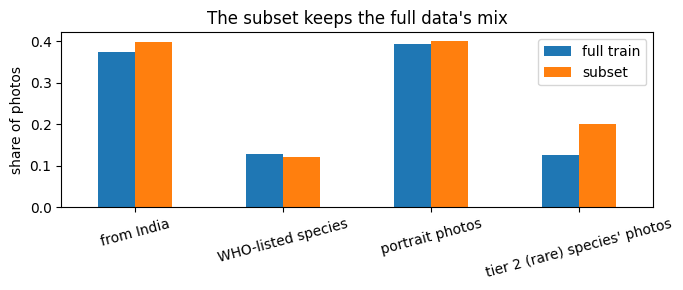

In [5]:
def shares(frame):
    return {"from India": frame["in_india"].mean(),
            "WHO-listed species": (frame["who_category"] != "not_listed").mean(),
            "portrait photos": (frame["height"] > 1.02 * frame["width"]).mean(),
            "tier 2 (rare) species' photos": (frame["tier"] == "tier2").mean()}


comparison = pd.DataFrame({"full train": shares(train), "subset": shares(subset)})
comparison.plot.bar(figsize=(7, 3), rot=15, title="The subset keeps the full data's mix")
plt.ylabel("share of photos")
plt.tight_layout()
comparison.round(3)

The one intended difference: rare (tier 2) species hold a bigger share of the subset than of full train. That is the floor of 20 doing its job, lifting rare species so the models see enough of them.

## 5. A calibration set the models never train on

Later notebooks fit decision thresholds (how confident the app must be before it says "dangerous"). Fitting those on training photos would flatter the model, so the calibration set holds training-split photos that are **not** in the subset and whose photographers have **no** photo in the subset either.

In [6]:
calibration = train[~train["path"].isin(subset["path"])
                   & ~train["observer_id"].isin(subset["observer_id"])]
print(f"{len(calibration):,} calibration photos in {calibration['species'].nunique()} species, "
      f"from {calibration['observer_id'].nunique():,} photographers the models never see")

7,999 calibration photos in 111 species, from 4,696 photographers the models never see


## 6. 200 photos to check by hand

Labels come from iNaturalist and are not perfect. We set aside 200 training photos, spread across common/rare tiers and WHO categories (at least 10 per group, the rest in proportion), to check by eye. The contact sheet is written next to the subset files. Every photo is Creative Commons; its licence and photographer credit are in `metadata.csv` under its id.

In [7]:
def stratified_200(train, n=200, floor=10, seed=SEED):
    """n photos spread over tier x WHO category: `floor` each, the rest in proportion."""
    sizes = train.groupby(["tier", "who_category"]).size()
    quotas = sizes.clip(upper=floor).astype(float)
    room = sizes - quotas
    quotas += np.floor(room * (n - quotas.sum()) / room.sum())
    quotas[sizes.index[: int(n - quotas.sum())]] += 1  # hand out the rounding remainder
    picked = [group.sample(n=int(quotas[key]), random_state=seed)
              for key, group in train.groupby(["tier", "who_category"])]
    return pd.concat(picked).reset_index(drop=True)


hand_check = stratified_200(train)
hand_check.to_csv(OUT / "hand_check.csv", index=False)
hand_check.groupby(["tier", "who_category"]).size().rename("photos").to_frame()

photos
tier  who_category        
tier1 1                 22
      2                 18
      not_listed       122
tier2 2                 10
      not_listed        28

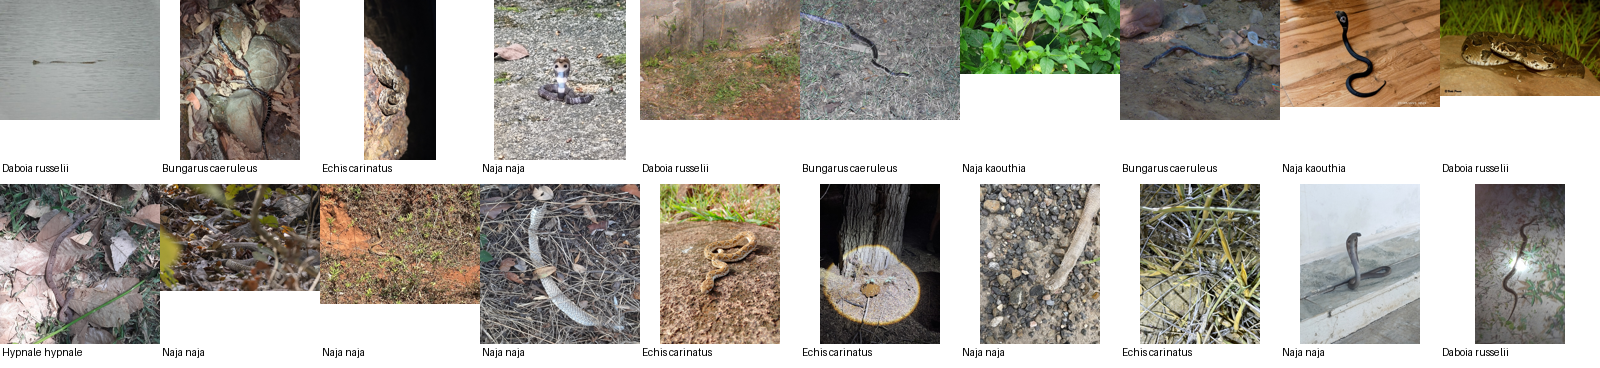

In [8]:
if (DATA / "data").exists():  # photo files live on the Kaggle dataset
    from PIL import Image, ImageDraw

    thumb, cols, label = 160, 10, 24
    sheet = Image.new("RGB", (cols * thumb, -(-len(hand_check) // cols) * (thumb + label)), "white")
    draw = ImageDraw.Draw(sheet)
    for i, row in enumerate(hand_check.itertuples()):
        with Image.open(DATA / "data" / row.path) as photo:
            tile = photo.convert("RGB")
            tile.thumbnail((thumb, thumb))
        left, top = (i % cols) * thumb, (i // cols) * (thumb + label)
        sheet.paste(tile, (left + (thumb - tile.width) // 2, top))
        draw.text((left + 2, top + thumb + 2), row.species[:28], fill="black")
    sheet.save(OUT / "hand_check_sheet.jpg", quality=85)
    display(sheet.crop((0, 0, sheet.width, 2 * (thumb + label))))  # first two rows as a preview
else:
    print("photo files live on the Kaggle dataset; the contact sheet is made when this runs there")

## 7. Save everything and check it

Every later run records the subset's SHA-256 hash, so we always know exactly which photos a result was trained on. The last check opens 20 random subset paths (and one made-up path that must **not** exist, to prove the check can fail).

In [9]:
subset[["path", "species", "observer_id", "split"]].to_csv(OUT / "subset.csv", index=False)
calibration[["path", "species", "observer_id", "split"]].to_csv(OUT / "calibration.csv", index=False)
(OUT / "subset_report.json").write_text(json.dumps(
    {"photos": len(subset), "share": len(subset) / len(train), "comparison": comparison.round(4).to_dict()}, indent=2))

digest = hashlib.sha256("\n".join(sorted(subset["path"])).encode()).hexdigest()
print(f"subset.csv written, {len(subset):,} rows; every run records this subset hash: {digest[:12]}...")

if (DATA / "data").exists():
    sample = subset.sample(20, random_state=42)
    missing = [p for p in sample["path"] if not (DATA / "data" / p).exists()]
    assert not missing, missing
    assert not (DATA / "data" / "train/not_a_species/made_up.jpg").exists()
    print("20 of 20 sampled subset paths exist; the made-up path does not")
else:
    print("photo files live on the Kaggle dataset; the 20-path check runs there")

subset.csv written, 13,925 rows; every run records this subset hash: 40196d19a68e...
20 of 20 sampled subset paths exist; the made-up path does not


## What we found

The subset has 13,925 photos, 16.4% of the training split, and keeps all 184 species. Its mix stays within about 2 points of the full data on the India, WHO-listed and portrait shares, and rare species are deliberately a little over-represented so models can learn them. A separate 7,999-photo calibration set, from photographers the models never see, is reserved for fitting thresholds. Every experiment in the next notebooks trains on exactly this subset, verified by its hash.